# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Benedictus Ryu Gunawan | 5054251001 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device yang digunakan:", device)

Device yang digunakan: cuda


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("data/fashion-mnist_train.csv")
test_df = pd.read_csv("data/fashion-mnist_test.csv")

print("Ukuran data train:", train_df.shape)
print("Ukuran data test :", test_df.shape)
display(train_df.head())

Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


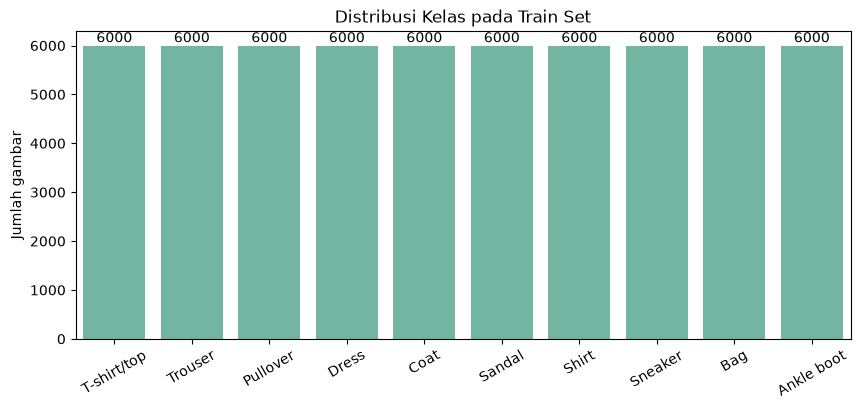

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
ax = sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values, color="#66c2a5")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.title("Distribusi Kelas pada Train Set")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=30)
plt.show()

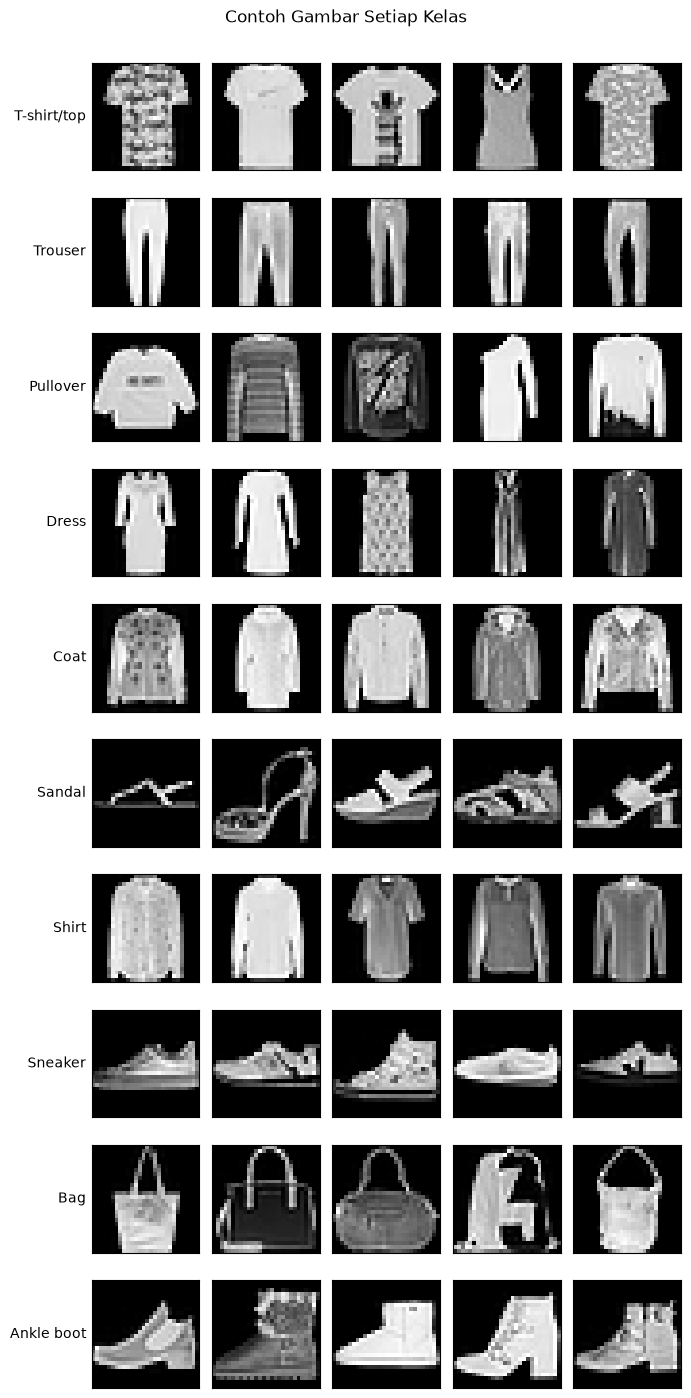

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, axes = plt.subplots(10, 5, figsize=(7, 14))
for label in range(10):
    samples = train_df[train_df["label"] == label].iloc[:5, 1:].values
    for j in range(5):
        ax = axes[label, j]
        ax.imshow(samples[j].reshape(28, 28), cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(class_names[label], rotation=0, ha="right", va="center")
plt.suptitle("Contoh Gambar Setiap Kelas", y=1.0)
plt.tight_layout()
plt.show()

**Kelas yang terlihat mirip secara visual:** T-shirt/top, Shirt, Pullover, dan Coat sama-sama berupa pakaian atasan dengan siluet badan dan dua lengan, sehingga pada resolusi 28×28 perbedaannya hanya pada panjang lengan dan detail kecil seperti kerah atau kancing. Dress juga mirip dengan atasan yang panjang. Di kelompok alas kaki, Sneaker dan Ankle boot punya bentuk dasar yang serupa, sedangkan Sandal lebih mudah dibedakan karena bentuknya berongga. Trouser dan Bag terlihat paling berbeda dari kelas lainnya.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Missing value train: 0 | test: 0


Rentang nilai piksel: 0 - 255
Proporsi piksel bernilai 0 (latar belakang): 0.5018


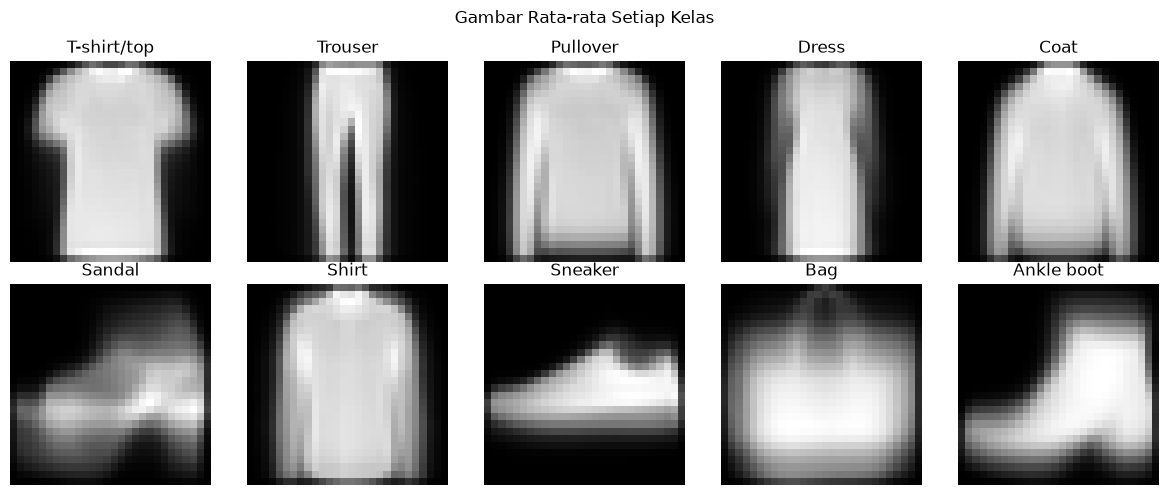

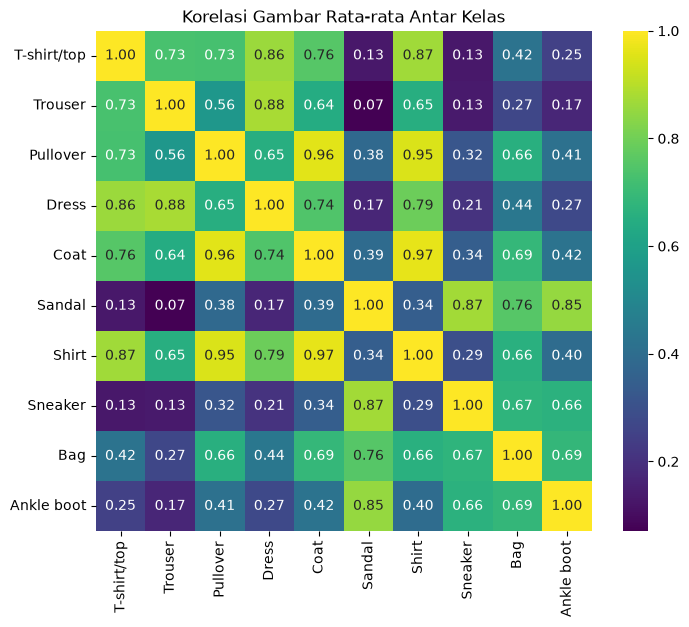

In [5]:
print("Missing value train:", int(train_df.isnull().sum().sum()), "| test:", int(test_df.isnull().sum().sum()))
pixels = train_df.iloc[:, 1:].values
print("Rentang nilai piksel:", pixels.min(), "-", pixels.max())
print("Proporsi piksel bernilai 0 (latar belakang):", round((pixels == 0).mean(), 4))

# Gambar rata-rata setiap kelas: menunjukkan siluet umum tiap kelas
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
mean_images = np.stack([pixels[train_df["label"].values == k].mean(axis=0) for k in range(10)])
for label, ax in enumerate(axes.flatten()):
    ax.imshow(mean_images[label].reshape(28, 28), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")
plt.suptitle("Gambar Rata-rata Setiap Kelas")
plt.tight_layout()
plt.show()

# Kemiripan antar kelas berdasarkan korelasi gambar rata-ratanya
plt.figure(figsize=(8, 6.5))
sns.heatmap(np.corrcoef(mean_images), annot=True, fmt=".2f", cmap="viridis",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Korelasi Gambar Rata-rata Antar Kelas")
plt.show()

**Ringkasan hasil EDA:**

- Train set berisi 60.000 gambar dan test set 10.000 gambar, tanpa missing value. Setiap kelas berjumlah sama (6.000 gambar di train), jadi dataset **seimbang** dan accuracy bisa dipakai sebagai metrik utama.
- Nilai piksel berada di rentang 0-255 dan sekitar 50% piksel bernilai 0 (latar belakang hitam).
- Korelasi gambar rata-rata menunjukkan kelompok atasan sangat mirip: Shirt-Coat 0,97, Pullover-Coat 0,96, Shirt-Pullover 0,95, Shirt-T-shirt/top 0,87. Kelompok alas kaki juga mirip: Sandal-Sneaker 0,87 dan Sandal-Ankle boot 0,85. Kelas-kelas ini diperkirakan paling sulit dibedakan model.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns=["label"]).values
y_test = test_df["label"].values
X_test = test_df.drop(columns=["label"]).values

print("X train:", X_train_full.shape, "| y train:", y_train_full.shape)
print("X test :", X_test.shape, "| y test :", y_test.shape)

X train: (60000, 784) | y train: (60000,)
X test : (10000, 784) | y test : (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full / 255.0
X_test = X_test / 255.0
print("Rentang nilai setelah normalisasi:", X_train_full.min(), "-", X_train_full.max())

Rentang nilai setelah normalisasi: 0.0 - 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED)

print("Train     :", X_train.shape)
print("Validation:", X_val.shape)
print("Test      :", X_test.shape)

Train     : (54000, 784)
Validation: (6000, 784)
Test      : (10000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

def to_dataset(X, y):
    return TensorDataset(torch.tensor(X, dtype=torch.float32).view(-1, 1, 28, 28),
                         torch.tensor(y, dtype=torch.long))

BATCH_SIZE = 64
train_loader = DataLoader(to_dataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(to_dataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(to_dataset(X_test, y_test), batch_size=BATCH_SIZE)

xb, yb = next(iter(train_loader))
print("Bentuk satu batch X:", xb.shape, xb.dtype, "| y:", yb.shape, yb.dtype)

Bentuk satu batch X: torch.Size([64, 1, 28, 28]) torch.float32 | y: torch.Size([64]) torch.int64


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),  # output berupa logit, tanpa Softmax
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(SEED)
model_ann = ANN().to(device)
print(model_ann)
print("Jumlah parameter:", count_params(model_ann))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

LR = 1e-3
EPOCHS = 15
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Loss dan accuracy rata-rata pada seluruh data di loader."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += criterion(logits, y).item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def train_model(model, epochs=EPOCHS, lr=LR):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, train_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        print(f"Epoch {epoch:>2}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f}")
    return history

histories = {}
histories["ANN"] = train_model(model_ann)

Epoch  1/15 | train loss 0.4226 acc 0.8459 | val loss 0.4375 acc 0.8405


Epoch  2/15 | train loss 0.3349 acc 0.8772 | val loss 0.3637 acc 0.8663


Epoch  3/15 | train loss 0.3006 acc 0.8902 | val loss 0.3465 acc 0.8705


Epoch  4/15 | train loss 0.2924 acc 0.8918 | val loss 0.3391 acc 0.8755


Epoch  5/15 | train loss 0.2763 acc 0.8971 | val loss 0.3296 acc 0.8820


Epoch  6/15 | train loss 0.2646 acc 0.9006 | val loss 0.3314 acc 0.8787


... (5 outputs left out)

Epoch 12/15 | train loss 0.2126 acc 0.9187 | val loss 0.3290 acc 0.8902


Epoch 13/15 | train loss 0.1909 acc 0.9278 | val loss 0.3142 acc 0.8915


Epoch 14/15 | train loss 0.1872 acc 0.9305 | val loss 0.3220 acc 0.8907


Epoch 15/15 | train loss 0.1746 acc 0.9349 | val loss 0.3289 acc 0.8888


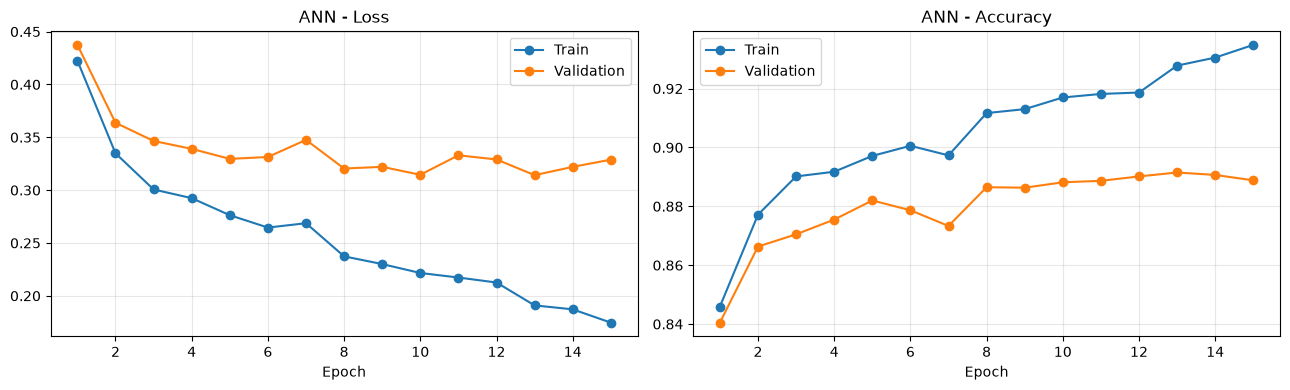

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(epochs, history[f"train_{metric}"], marker="o", label="Train")
        ax.plot(epochs, history[f"val_{metric}"], marker="o", label="Validation")
        ax.set_title(f"{title} - {'Loss' if metric == 'loss' else 'Accuracy'}")
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(histories["ANN"], "ANN")

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, _ in loader:
            preds.append(model(x.to(device)).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

predictions = {}
predictions["ANN"] = predict(model_ann, test_loader)
print("Accuracy test ANN:", round(accuracy_score(y_test, predictions["ANN"]), 4))

Accuracy test ANN: 0.8951


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
model_cnn = SimpleCNN().to(device)
print(model_cnn)
print("Jumlah parameter:", count_params(model_cnn))

# Perhitungan manual ukuran output dengan rumus (W - K + 2P) / S + 1:
#   Input                           : 1 x 28 x 28
#   Conv2d(1, 32, K=3, P=1, S=1)    : (28 - 3 + 2*1) / 1 + 1 = 28  -> 32 x 28 x 28
#   MaxPool2d(K=2, S=2)             : (28 - 2 + 0) / 2 + 1   = 14  -> 32 x 14 x 14
#   Conv2d(32, 64, K=3, P=1, S=1)   : (14 - 3 + 2*1) / 1 + 1 = 14  -> 64 x 14 x 14
#   MaxPool2d(K=2, S=2)             : (14 - 2 + 0) / 2 + 1   = 7   -> 64 x 7 x 7
#   Flatten                         : 64 * 7 * 7 = 3136 -> ukuran input nn.Linear pertama
dummy = torch.zeros(1, 1, 28, 28).to(device)
out = dummy
print("\nBentuk output setiap layer pada bagian konvolusi:")
for layer in model_cnn.features:
    out = layer(out)
    print(f"  {layer.__class__.__name__:<10} -> {tuple(out.shape)}")
print("Ukuran setelah Flatten:", out.flatten(1).shape[1], "(perhitungan manual: 64 * 7 * 7 =", 64 * 7 * 7, ")")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642

Bentuk output setiap layer pada bagian konvolusi:


  Conv2d     -> (1, 32, 28, 28)
  ReLU       -> (1, 32, 28, 28)
  MaxPool2d  -> (1, 32, 14, 14)
  Conv2d     -> (1, 64, 14, 14)
  ReLU       -> (1, 64, 14, 14)
  MaxPool2d  -> (1, 64, 7, 7)
Ukuran setelah Flatten: 3136 (perhitungan manual: 64 * 7 * 7 = 3136 )


Epoch  1/15 | train loss 0.3498 acc 0.8719 | val loss 0.3635 acc 0.8680


Epoch  2/15 | train loss 0.2669 acc 0.9038 | val loss 0.2932 acc 0.8948


Epoch  3/15 | train loss 0.2208 acc 0.9198 | val loss 0.2594 acc 0.9055


Epoch  4/15 | train loss 0.2007 acc 0.9269 | val loss 0.2444 acc 0.9117


Epoch  5/15 | train loss 0.2052 acc 0.9233 | val loss 0.2672 acc 0.9035


Epoch  6/15 | train loss 0.1719 acc 0.9350 | val loss 0.2407 acc 0.9127


... (5 outputs left out)

Epoch 12/15 | train loss 0.0756 acc 0.9731 | val loss 0.2688 acc 0.9190


Epoch 13/15 | train loss 0.0795 acc 0.9715 | val loss 0.3033 acc 0.9073


Epoch 14/15 | train loss 0.0587 acc 0.9785 | val loss 0.2958 acc 0.9137


Epoch 15/15 | train loss 0.0431 acc 0.9855 | val loss 0.3106 acc 0.9153


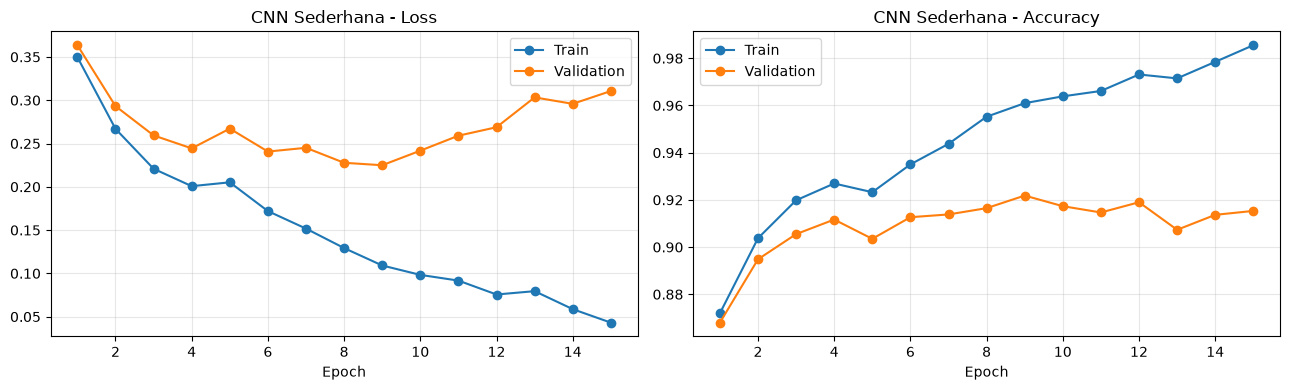

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

histories["CNN Sederhana"] = train_model(model_cnn)
plot_history(histories["CNN Sederhana"], "CNN Sederhana")

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

predictions["CNN Sederhana"] = predict(model_cnn, test_loader)
print("Accuracy test CNN Sederhana:", round(accuracy_score(y_test, predictions["CNN Sederhana"]), 4))

Accuracy test CNN Sederhana: 0.924


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNNBatchNormDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
model_cnn_bn = CNNBatchNormDropout().to(device)
print(model_cnn_bn)
print("Jumlah parameter:", count_params(model_cnn_bn))

CNNBatchNormDropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch  1/15 | train loss 0.3394 acc 0.8704 | val loss 0.3590 acc 0.8665


Epoch  2/15 | train loss 0.2602 acc 0.9020 | val loss 0.2940 acc 0.8920


Epoch  3/15 | train loss 0.2053 acc 0.9245 | val loss 0.2482 acc 0.9108


Epoch  4/15 | train loss 0.2300 acc 0.9123 | val loss 0.2897 acc 0.8943


Epoch  5/15 | train loss 0.1800 acc 0.9316 | val loss 0.2414 acc 0.9150


Epoch  6/15 | train loss 0.1783 acc 0.9314 | val loss 0.2479 acc 0.9115


... (5 outputs left out)

Epoch 12/15 | train loss 0.1371 acc 0.9453 | val loss 0.2664 acc 0.9075


Epoch 13/15 | train loss 0.1135 acc 0.9565 | val loss 0.2552 acc 0.9137


Epoch 14/15 | train loss 0.0908 acc 0.9644 | val loss 0.2526 acc 0.9207


Epoch 15/15 | train loss 0.0846 acc 0.9681 | val loss 0.2447 acc 0.9213


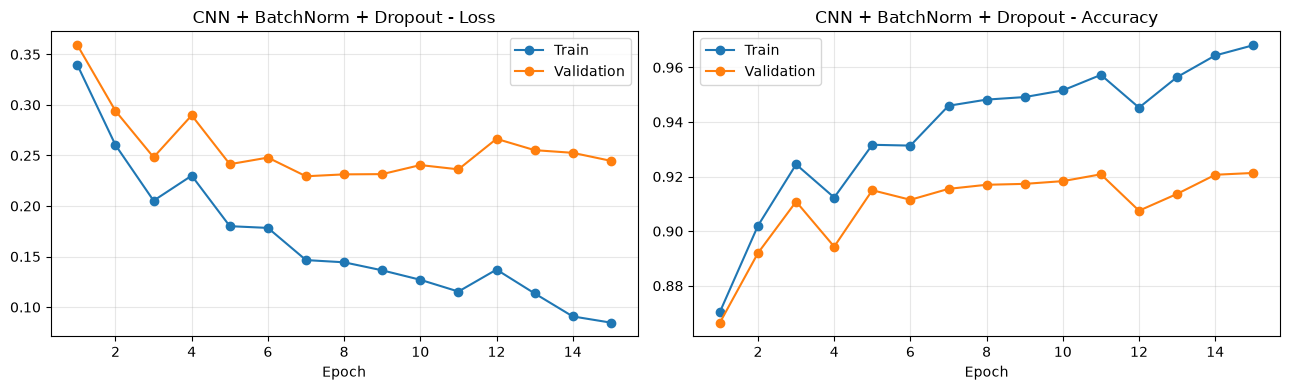

ANN                        | acc train 0.9349 val 0.8888 (selisih +0.0460) | loss train 0.1746 val 0.3289 | val loss terendah di epoch 13
CNN Sederhana              | acc train 0.9855 val 0.9153 (selisih +0.0702) | loss train 0.0431 val 0.3106 | val loss terendah di epoch 9
CNN + BatchNorm + Dropout  | acc train 0.9681 val 0.9213 (selisih +0.0468) | loss train 0.0846 val 0.2447 | val loss terendah di epoch 7


In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

# train_model memanggil model.train() saat update bobot dan model.eval() (lewat evaluate) saat menghitung metrik
histories["CNN + BatchNorm + Dropout"] = train_model(model_cnn_bn)
plot_history(histories["CNN + BatchNorm + Dropout"], "CNN + BatchNorm + Dropout")

# Selisih train vs validation di epoch terakhir sebagai indikator overfitting
for name, h in histories.items():
    print(f"{name:<26} | acc train {h['train_acc'][-1]:.4f} val {h['val_acc'][-1]:.4f} "
          f"(selisih {h['train_acc'][-1] - h['val_acc'][-1]:+.4f}) | loss train {h['train_loss'][-1]:.4f} "
          f"val {h['val_loss'][-1]:.4f} | val loss terendah di epoch {int(np.argmin(h['val_loss'])) + 1}")

**Perbandingan selisih train dan validation dengan model 3.2:**

- **CNN Sederhana (3.2):** train accuracy naik sampai 0,9855 dan train loss turun sampai 0,0431, tetapi validation loss terendah di epoch 9 (0,2249) lalu naik terus sampai 0,3106. Selisih accuracy train-validation di akhir adalah 0,0702. Ini overfitting yang jelas.
- **CNN + BatchNorm + Dropout (3.3):** train accuracy 0,9681 dan validation accuracy 0,9213, selisihnya 0,0468. Validation loss di akhir 0,2447, jauh lebih rendah dari model 3.2 (0,3106) dan tidak naik terus seperti pada 3.2. Kurvanya lebih berfluktuasi (misalnya epoch 4 dan 12), tetapi selisih train-validation lebih kecil, artinya overfitting berkurang.

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

predictions["CNN + BatchNorm + Dropout"] = predict(model_cnn_bn, test_loader)
print("Accuracy test CNN + BatchNorm + Dropout:",
      round(accuracy_score(y_test, predictions["CNN + BatchNorm + Dropout"]), 4))

Accuracy test CNN + BatchNorm + Dropout: 0.9276


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

models = {"ANN": model_ann, "CNN Sederhana": model_cnn, "CNN + BatchNorm + Dropout": model_cnn_bn}

metrics = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="macro"),
        "Recall": recall_score(y_test, pred, average="macro"),
        "F1-Score": f1_score(y_test, pred, average="macro"),
        "Val Accuracy": histories[name]["val_acc"][-1],
        "Jumlah Parameter": count_params(models[name]),
    }
    for name, pred in predictions.items()
]).set_index("Model")
display(metrics.round(4))

,Accuracy,Precision,Recall,F1-Score,Val Accuracy,Jumlah Parameter
Model,,,,,,
ANN,0.8951,0.8953,0.8951,0.8946,0.8888,235146
CNN Sederhana,0.9240,0.9246,0.9240,0.9240,0.9153,421642
CNN + BatchNorm + Dropout,0.9276,0.9277,0.9276,0.9272,0.9213,421834


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

# Model terbaik dipilih dari validation accuracy (bukan dari test set)
best_name = max(histories, key=lambda n: histories[n]["val_acc"][-1])
best_model, best_pred = models[best_name], predictions[best_name]
print("Model terbaik:", best_name, "\n")
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Model terbaik: CNN + BatchNorm + Dropout 

              precision    recall  f1-score   support

 T-shirt/top     0.8430    0.9130    0.8766      1000
     Trouser     0.9900    0.9910    0.9905      1000
    Pullover     0.8684    0.9170    0.8920      1000
       Dress     0.9287    0.9380    0.9333      1000
        Coat     0.9243    0.8550    0.8883      1000
      Sandal     0.9919    0.9820    0.9869      1000
       Shirt     0.8076    0.7470    0.7761      1000
     Sneaker     0.9708    0.9640    0.9674      1000
         Bag     0.9890    0.9870    0.9880      1000
  Ankle boot     0.9637    0.9820    0.9728      1000

    accuracy                         0.9276     10000
   macro avg     0.9277    0.9276    0.9272     10000
weighted avg     0.9277    0.9276    0.9272     10000



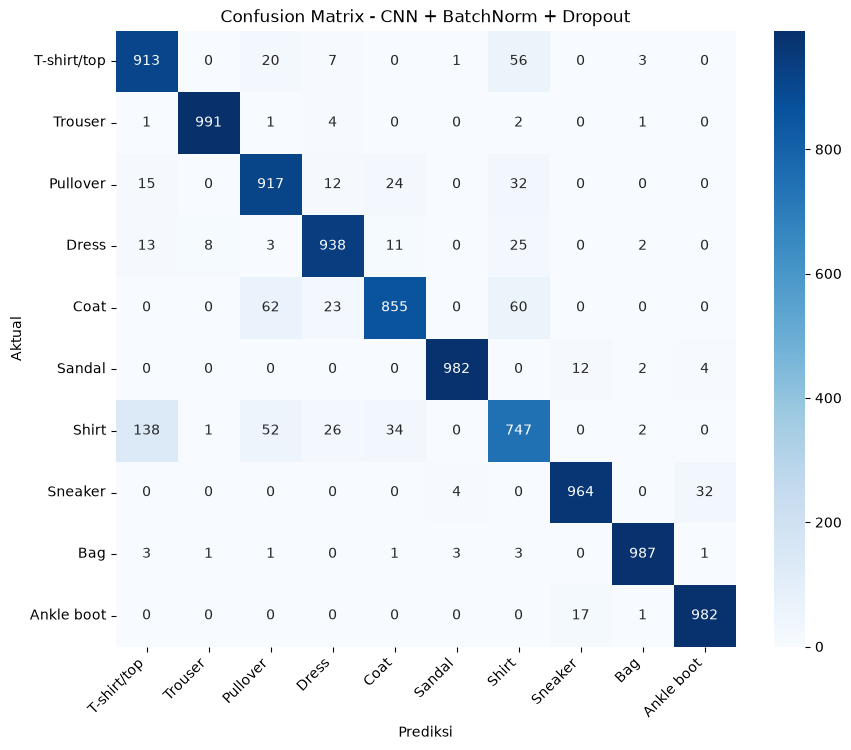

Pasangan kelas yang paling sering tertukar (aktual -> prediksi):
  Shirt        -> T-shirt/top : 138 gambar
  Coat         -> Pullover    : 62 gambar
  Coat         -> Shirt       : 60 gambar
  T-shirt/top  -> Shirt       : 56 gambar
  Shirt        -> Pullover    : 52 gambar
  Shirt        -> Coat        : 34 gambar
  Pullover     -> Shirt       : 32 gambar
  Sneaker      -> Ankle boot  : 32 gambar


In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=45, ha="right")
plt.show()

# Pasangan kelas (aktual -> prediksi) yang paling sering tertukar
errors = cm.copy()
np.fill_diagonal(errors, 0)
top = np.dstack(np.unravel_index(np.argsort(errors, axis=None)[::-1][:8], errors.shape))[0]
print("Pasangan kelas yang paling sering tertukar (aktual -> prediksi):")
for actual, predicted in top:
    print(f"  {class_names[actual]:<12} -> {class_names[predicted]:<12}: {errors[actual, predicted]} gambar")

**Pasangan kelas yang paling sering tertukar:** kesalahan terbesar adalah **Shirt yang diprediksi sebagai T-shirt/top (138 gambar)**, lalu Coat → Pullover (62), Coat → Shirt (60), T-shirt/top → Shirt (56), dan Shirt → Pullover (52). Hampir semua kesalahan terjadi di antara kelas atasan (T-shirt/top, Pullover, Coat, Shirt). Di luar kelompok itu, yang paling sering tertukar adalah Sneaker → Ankle boot (32). Ini sesuai dengan kemiripan yang terlihat pada EDA.

Jumlah gambar test yang salah diklasifikasikan: 724 dari 10000


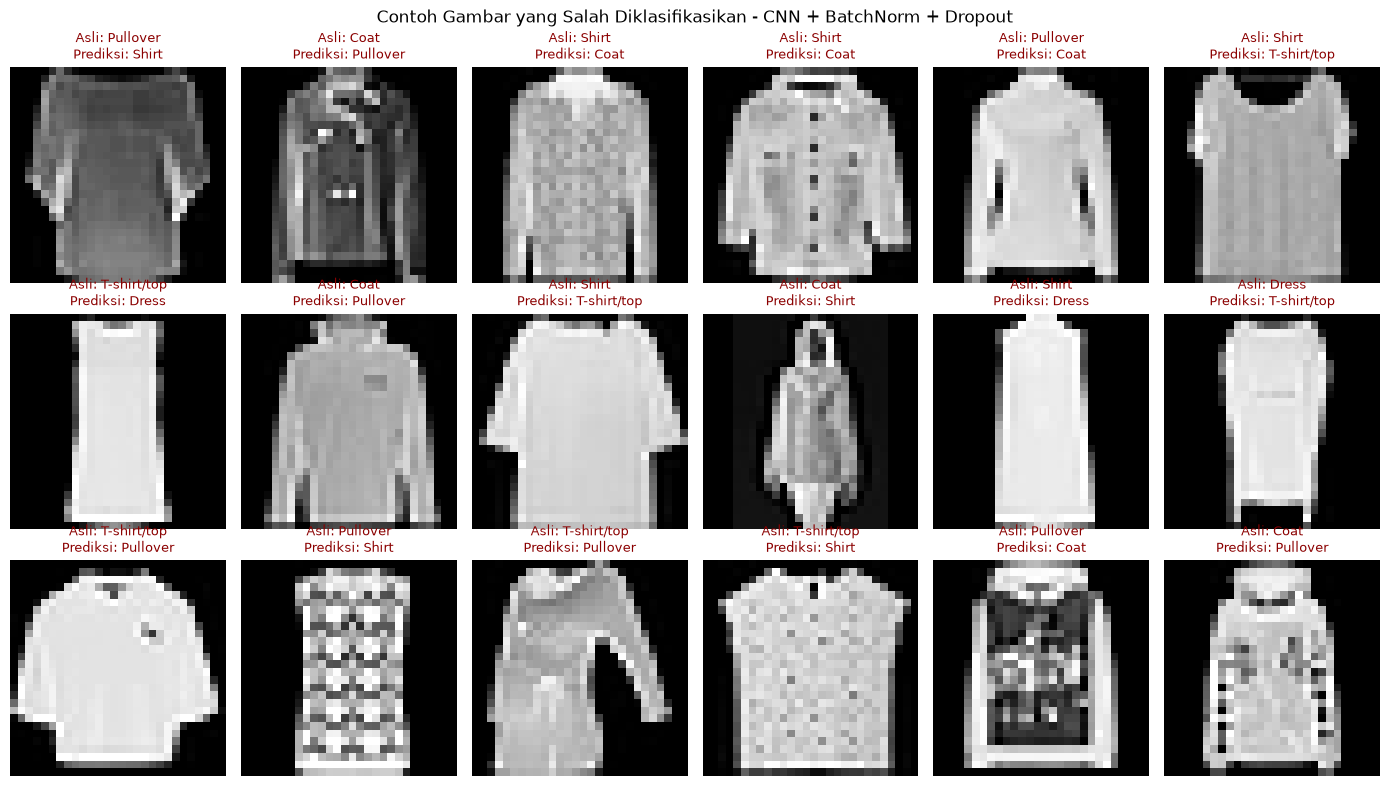

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

wrong = np.where(best_pred != y_test)[0]
print(f"Jumlah gambar test yang salah diklasifikasikan: {len(wrong)} dari {len(y_test)}")

fig, axes = plt.subplots(3, 6, figsize=(14, 8))
for ax, idx in zip(axes.flatten(), wrong):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test[idx]]}\nPrediksi: {class_names[best_pred[idx]]}", fontsize=9, color="darkred")
    ax.axis("off")
plt.suptitle(f"Contoh Gambar yang Salah Diklasifikasikan - {best_name}")
plt.tight_layout()
plt.show()

Bentuk feature map: (32, 28, 28)


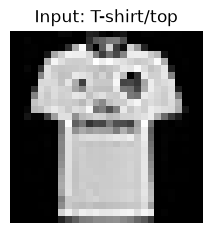

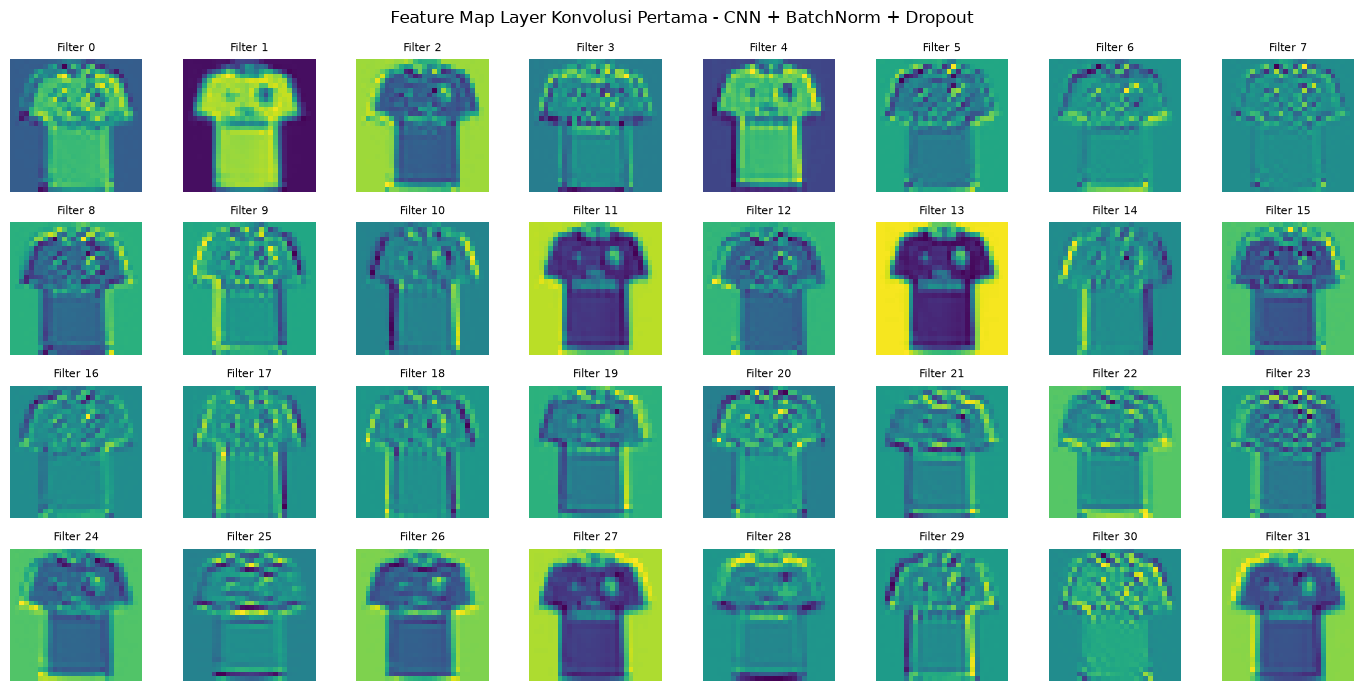

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

sample_idx = 0
x = torch.tensor(X_test[sample_idx], dtype=torch.float32).view(1, 1, 28, 28).to(device)

best_model.eval()
with torch.no_grad():
    feature_maps = best_model.features[0](x)  # hanya layer konvolusi pertama
feature_maps = feature_maps.detach().cpu().numpy()[0]
print("Bentuk feature map:", feature_maps.shape)

plt.figure(figsize=(2.5, 2.5))
plt.imshow(X_test[sample_idx].reshape(28, 28), cmap="gray")
plt.title(f"Input: {class_names[y_test[sample_idx]]}")
plt.axis("off")
plt.show()

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"Filter {i}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Feature Map Layer Konvolusi Pertama - {best_name}")
plt.tight_layout()
plt.show()

**Pola yang ditangkap filter layer konvolusi pertama** (untuk satu gambar T-shirt/top):

- **Bagian dalam objek / kecerahan:** filter 1 dan 4 aktif kuat pada seluruh area pakaian, mirip versi halus dari gambar aslinya.
- **Latar belakang:** filter 2, 11, 13, dan 27 justru aktif pada latar belakang dan rendah pada objek (kebalikan dari gambar asli), sehingga memisahkan objek dari latar.
- **Tepi vertikal:** filter 9, 14, 17, dan 18 menyala pada sisi kiri atau kanan badan dan lengan.
- **Tepi horizontal:** filter 21, 25, dan 28 menyala pada garis bahu, ujung lengan, dan tepi bawah baju.
- **Tekstur / detail kecil:** filter 0, 3, dan 30 merespons motif di bagian dada.

Jadi layer pertama mempelajari fitur tingkat rendah (tepi dengan arah berbeda, kontras objek-latar, tekstur) yang kemudian digabungkan oleh layer berikutnya menjadi bentuk pakaian.

In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

# Definisi class model terbaik ada pada bagian 3 notebook ini (CNNBatchNormDropout / SimpleCNN / ANN).
# Saat deployment, class tersebut harus didefinisikan ulang sebelum memanggil load_state_dict.
torch.save(best_model.state_dict(), "model.pth")
print(f"Bobot model '{best_name}' (class {best_model.__class__.__name__}) disimpan ke model.pth")

# Cek: bobot yang disimpan bisa dimuat ulang dan menghasilkan prediksi yang sama
reloaded = best_model.__class__().to(device)
reloaded.load_state_dict(torch.load("model.pth", map_location=device))
assert (predict(reloaded, test_loader) == best_pred).all()
print("Model berhasil dimuat ulang, prediksi identik dengan model asli.")

Bobot model 'CNN + BatchNorm + Dropout' (class CNNBatchNormDropout) disimpan ke model.pth
Model berhasil dimuat ulang, prediksi identik dengan model asli.


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Ringkasan hasil pada test set (10.000 gambar):**

| Model | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Parameter |
|---|---|---|---|---|---|
| ANN | 0,8951 | 0,8953 | 0,8951 | 0,8946 | 235.146 |
| CNN Sederhana | 0,9240 | 0,9246 | 0,9240 | 0,9240 | 421.642 |
| CNN + BatchNorm + Dropout | 0,9276 | 0,9277 | 0,9276 | 0,9272 | 421.834 |

Ketiga model dilatih dengan pengaturan yang sama: Adam, learning rate 0,001, batch size 64, 15 epoch.

**1. ANN vs CNN**

CNN Sederhana menaikkan accuracy test dari 0,8951 menjadi 0,9240, artinya jumlah gambar yang salah turun dari 1.049 menjadi 760 (berkurang sekitar 28%).

ANN meratakan gambar menjadi vektor 784 nilai, sehingga informasi piksel mana yang bertetangga hilang dan setiap piksel diperlakukan sebagai fitur terpisah. CNN memakai filter 3×3 yang digeser ke seluruh gambar, sehingga pola lokal seperti tepi dan tekstur dipelajari satu kali lalu dipakai di semua posisi (weight sharing), dan MaxPool membuat model lebih tahan terhadap pergeseran kecil.

Soal jumlah parameter: CNN memang punya parameter lebih banyak (421.642 vs 235.146), tetapi 401.536 di antaranya ada di layer `Linear(3136, 128)` setelah Flatten. Kedua layer konvolusi hanya punya 320 + 18.496 = 18.816 parameter. Jadi bagian yang membedakan CNN dari ANN sangat kecil dibanding total parameternya, dan peningkatan performa lebih masuk akal dijelaskan oleh cara CNN memproses gambar daripada oleh jumlah parameter. Eksperimen ini tidak memisahkan kedua faktor tersebut secara ketat karena jumlah parameter kedua model tidak disamakan.

**2. Pengaruh Batch Normalization dan Dropout**

BatchNorm hanya menambah 192 parameter (421.834 vs 421.642) dan Dropout tidak menambah parameter. Pengaruhnya terlihat pada learning curve:

- **CNN Sederhana:** train loss turun sampai 0,0431 (train accuracy 0,9855), tetapi validation loss terendah di epoch 9 (0,2249) lalu naik sampai 0,3106. Selisih accuracy train-validation 0,0702. Model mulai menghafal data train.
- **CNN + BatchNorm + Dropout:** train accuracy lebih rendah (0,9681), validation accuracy lebih tinggi (0,9213 vs 0,9153), validation loss akhir 0,2447, dan selisih accuracy turun menjadi 0,0468. Dropout 0,5 membuat model tidak bisa bergantung pada neuron tertentu sehingga overfitting berkurang. Kurva validation-nya lebih naik-turun antar epoch.
- **ANN:** validation loss berhenti membaik di sekitar 0,32 sejak epoch 8 sementara train loss terus turun, dengan selisih accuracy 0,0460. ANN juga overfitting ringan, tetapi masalah utamanya adalah batas performanya lebih rendah.

Di test set, peningkatan dari BatchNorm + Dropout kecil: 0,9276 vs 0,9240 (selisih 36 gambar dari 10.000). Karena hanya dari satu kali training dengan satu seed, selisih ini belum cukup untuk menyimpulkan bahwa accuracy-nya pasti lebih baik. Yang lebih jelas adalah perbaikan pada validation loss dan berkurangnya selisih train-validation.

**3. Kelas yang sulit dibedakan**

Dari classification report model terbaik (CNN + BatchNorm + Dropout):

- Paling mudah: Trouser (F1 0,9905), Bag (0,9880), Sandal (0,9869), Ankle boot (0,9728), Sneaker (0,9674).
- Paling sulit: **Shirt** (F1 0,7761, recall hanya 0,7470), lalu T-shirt/top (0,8766), Coat (0,8883), dan Pullover (0,8920).

Dari 724 gambar yang salah, yang terbanyak adalah Shirt → T-shirt/top (138), Coat → Pullover (62), Coat → Shirt (60), T-shirt/top → Shirt (56), dan Shirt → Pullover (52). Keempat kelas ini sama-sama pakaian atasan dengan siluet yang hampir sama, dan pada resolusi 28×28 grayscale detail pembeda seperti kerah, kancing, atau bahan sulit terlihat. Hal ini sudah terlihat di EDA dari korelasi gambar rata-rata (Shirt-Coat 0,97, Pullover-Coat 0,96, Shirt-Pullover 0,95).

Sebaliknya, Trouser dan Dress punya korelasi gambar rata-rata tinggi (0,88) tetapi jarang tertukar (precision dan recall Trouser 0,99). Jadi kemiripan rata-rata piksel saja tidak selalu menentukan; CNN bisa memakai bentuk lokal seperti celah di antara dua kaki celana.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**

1. CNN lebih baik dari ANN untuk klasifikasi gambar Fashion-MNIST: accuracy test 0,9240 (CNN Sederhana) dan 0,9276 (CNN + BatchNorm + Dropout) dibanding 0,8951 (ANN).
2. Bagian konvolusi CNN hanya berisi 18.816 parameter, sehingga keunggulannya lebih berkaitan dengan cara memproses gambar (pola lokal, weight sharing, pooling) daripada jumlah parameter.
3. CNN Sederhana overfitting setelah sekitar epoch 9 (validation loss naik dari 0,2249 ke 0,3106). Batch Normalization dan Dropout menurunkan selisih accuracy train-validation dari 0,0702 menjadi 0,0468 dan validation loss akhir menjadi 0,2447, dengan peningkatan accuracy test yang kecil (+0,0036).
4. Kesalahan terpusat pada kelas atasan yang mirip, terutama Shirt (F1 0,7761) yang sering tertukar dengan T-shirt/top, Pullover, dan Coat.
5. Model terbaik, **CNN + BatchNorm + Dropout**, disimpan ke `model.pth` untuk tugas Deployment.

**Saran**

- Memakai early stopping atau menyimpan checkpoint dengan validation loss terendah, karena kedua CNN mencapai validation loss terbaik sebelum epoch 10.
- Menambahkan data augmentation (misalnya horizontal flip dan pergeseran kecil) untuk mengurangi overfitting dan membantu membedakan kelas atasan.
- Mencoba arsitektur yang lebih dalam (blok konvolusi ketiga) atau mengganti `Linear(3136, 128)` dengan global average pooling agar jumlah parameter jauh berkurang.
- Mencoba learning rate scheduler atau weight decay.
- Mengulang training dengan beberapa seed untuk memastikan selisih kecil antara kedua CNN memang konsisten.